# Parameter Estimation Tutorial

## Overview

This notebook demonstrates how to perform parameter estimation for precipitation 
conversion models using data we obtained from Minteq 
simulations of equilibrium precipitation. 

The parameter estimation workflow in this tutorial includes:

- Defining a mathematical model for precipitation conversion
- Importing all the necessary libraries and data
- Solving the estimation problem using least-squares methods for one species
- Visualizing model predictions
- Extending parameter estimation to multiple species
- Comparing results with both Minteq simulations and experimental data

## Mathematical Model

The precipitation conversion model is defined as:

$Conversion = \exp\left(-(\frac{\epsilon}{\text{Oxalic Acid Dosage}})^{n_{DA}}\right)$

where:

- Conversion: the fraction of species precipitated
- Oxalic Acid Dosage: the amount of oxalic acid added into the precipitator [mg/L]
- $\epsilon$: an empirical model parameter
- $n_{DA}$: an empirical model parameter

The objective of this tutorial is to determine the values of $\epsilon$ and $n_{DA}$ that
can reproduce the simulation data.

## Data Source

The data used in this tutorial were generated using equilibrium simulations
from Minteq. These data represent the precipitation behavior of critical minerals under different
oxalic acid dosages.

## Learning Objectives

After completing this tutorial, users should be able to:

1. Import the necessary libraries
2. Estimate parameters for one species
3. Extend parameter estimation to multiple species
4. Visualize results and compare with experimental data

## Step 1: Import Libraries

In this section, we import the Python packages required for parameter estimation,
data handling, and visualization. The tutorial uses the following major libraries:

 - Pyomo
 - IDAES
 - NumPy
 - Pandas
 - Matplotlib

In [23]:
# Import Pyomo's math and parameter estimation libraries
import pyomo.environ as pyo
from pyomo.environ import exp
import pyomo.contrib.parmest.parmest as parmest
from pyomo.contrib.parmest.experiment import Experiment

# Import degrees of freedom function from IDAES for sanity check
from idaes.core.util.model_statistics import degrees_of_freedom

# Import data frame, math and plotting libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Step 2: Estimate Parameters

This section demonstrates the workflow to estimate model parameters for one species using the Pyomo Parmest framework.

The workflow consists of four steps:

1. Import data
2. Build the parameter estimation problem
3. Solve for optimal parameters
4. Evaluate results

The objective is to determine model parameters that minimize the
difference between the Minteq data and the PrOMMiS model predictions.

### 2.1 Read Data File and Display

We import precipitation conversion data from a CSV file.

The dataset contains:

- Oxalic acid dosage amount
- Precipitation conversion for each species

In [24]:
# Load data from csv
data = pd.read_csv("precipitation_isotherm_data.csv")

### 2.2 Define the Model for Precipitation

We define the mathematical model used for precipitation simulation.

The model describes precipitation conversion as a function of oxalic
acid dosage using a nonlinear expression:

$Conversion = \exp\left(-(\frac{\epsilon}{\text{Oxalic Acid Dosage}})^{n_{DA}}\right)$

The unknown parameters are:

- $\epsilon$ (`eps`) — a model coefficient controlling precipitation intensity
- $n_{DA}$ (`n_DA`) — an exponent describing the acid dosage sensitivity


In [25]:
def isotherm():

    # Todo: Create a ConcreteModel object
    m = pyo.ConcreteModel()

    # Set up variables of the model
    m.n_DA = pyo.Var(initialize=2)
    m.eps = pyo.Var(initialize=1)
    # Conversion variable
    m.conversion = pyo.Var(initialize=0.1, bounds=(1e-8, 1))
    # Acid dosage variable (mg/L)
    m.oxalic_dosage = pyo.Var(initialize=0.1, bounds=(1e-8, 30))

    # Set bounds on fitted parameters
    # These ranges for bounds are reasonable search windows 
    # for fitting those parameters instead of hard physical limits
    m.n_DA.setlb(1)
    m.n_DA.setub(5)

    m.eps.setlb(1)
    m.eps.setub(5)

    m.conversion_rule = pyo.Constraint(expr=(m.conversion == exp(-((m.eps / (m.oxalic_dosage)) ** m.n_DA))))

    # Fix variables to have 0 Degrees of Freedom (DoF)
    m.n_DA.fix(2)
    m.eps.fix(1)
    m.oxalic_dosage.fix(1.425119)

    # Return initialized precipitation model
    return m

### 2.3 Define Nd Precipitation Experiment 

We define a class for the precipitation system.

Each experiment corresponds to one row of the dataset and contains:

- Input (oxalic acid dosage)
- Measured outputs (conversion)

In [26]:
# Create precipitation class
class PrecipitationExperiment(Experiment):

    # Define data
    def __init__(self, data, experiment_number):
        self.data = data
        self.experiment_number = experiment_number
        self.data_i = data.iloc[experiment_number, :]
        self.model = None

    # Create a model based on the isotherm model
    def create_model(self):
        self.model = m = isotherm()
        return m

    # Define inputs and outputs of the experiment
    def finalize_model(self):
        m = self.model

        # Experiment inputs values
        m.oxalic_dosage = self.data_i["Oxalate-2"]

        # Experiment output values
        m.conversion = self.data_i["Nd2(C2O4)3(s)"]

        return m

    # Label the parameters to be calculated
    def label_model(self):
        m = self.model

        m.experiment_outputs = pyo.Suffix(direction=pyo.Suffix.LOCAL)
        m.experiment_outputs.update(
            [
                (m.conversion, self.data_i["Nd2(C2O4)3(s)"]),
            ]
        )

        # Specify unknown parameters
        m.unknown_parameters = pyo.Suffix(direction=pyo.Suffix.LOCAL)
        m.unknown_parameters.update((k, pyo.ComponentUID(k)) for k in [m.n_DA, m.eps])

        return m

    def get_labeled_model(self):
        m = self.create_model()
        m = self.finalize_model()
        m = self.label_model()

        return m

### Sanity Check

After we define the precipitator unit model, we test the model and do a sanity check to ensure the system has zero degrees of freedom.

In [27]:
# Testing the initialized model
test_data = {"oxalic_dosage": 1.425119}

m = isotherm()

m.oxalic_dosage = test_data["oxalic_dosage"]

# Check that there are zero degrees of freedom
print("Degrees of Freedom = ", degrees_of_freedom(m))

Degrees of Freedom =  0


### 2.4 Finish setting up the experiment

We complete the parameter estimation problem definition here.

This includes:

- Defining the parameters to be estimated
- Defining the objective function

The objective function is defined as the sum of squared errors (SSE)
between:

- Minteq conversion values
- Model predicted conversion values


In [28]:
# Create a list of vars to estimate
variable_name = [
    "n_DA",
    "eps",
]

We need to provide a method to return an expression to compute the sum of squared errors that will be used as the objective in solving the parameter estimation problem. For this problem, the error will be computed for the conversion of REEs from ions to oxides.


In [29]:
# Create method to return an expression that computes the sum of squared error
def SSE(m):
    expr = sum(((y - y_hat)) ** 2 for y, y_hat in m.experiment_outputs.items())
    return expr * 1e4

### 2.5 Solve the Parameter Estimation Model

We solve the parameter estimation problem.

The steps include:

1. Create a list of experiments
2. Initialize a Parmest Estimator object
3. Solve the optimization problem

Parmest function automatically:

- Builds the optimization model
- Aggregates all experiments
- Minimizes the objective function

The solver determines the parameter values that best fit the
imported data.

In [30]:
# Initialize a parameter estimation object
exp_list = []
for i in range(data.shape[0]):
    exp_list.append(PrecipitationExperiment(data, i))

# Call solver
solver_options = {"tol": 1e-8}

# Define Estimator
pest = parmest.Estimator(
    exp_list, obj_function=SSE, solver_options=solver_options, tee=True
)

# Run parameter estimation using all data
obj_value, parameters = pest.theta_est()

Ipopt 3.13.2: tol=1e-08


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit http://projects.coin-or.org/Ipopt

This version of Ipopt was compiled from source code available at
    https://github.com/IDAES/Ipopt as part of the Institute for the Design of
    Advanced Energy Systems Process Systems Engineering Framework (IDAES PSE
    Framework) Copyright (c) 2018-2019. See https://github.com/IDAES/idaes-pse.

This version of Ipopt was compiled using HSL, a collection of Fortran codes
    for large-scale scientific computation.  All technical papers, sales and
    publicity material resulting from use of the HSL codes within IPOPT must
    contain the following acknowledgement:
        HSL, a collection of Fortran codes for large-scale scientific
        computation. S

### 2.6 Display Results

After solving the parameter estimation problem, the optimized parameter values
are displayed here.

The estimated parameters will be used in the next section to evaluate
model performance and generate plots.

In [31]:
print()
print("The values for the parameters are as follows:")
for k, v in parameters.items():
    print(f"{k} = {v:.3f}")


The values for the parameters are as follows:
n_DA = 2.419
eps = 1.010


## Step 3: Visualizing Results

After estimating the model parameters, it is important to evaluate how
well the model fits the actual data.

This section generates plots that compare:

- Measured conversion values
- Model predicted conversion values

The following types of plots are generated:

- Conversion vs. acid dosage amount plots
- Parity plots

These plots allow users to determine whether the estimated parameters
provide an adequate representation of the precipitation behavior.

<function matplotlib.pyplot.show(close=None, block=None)>

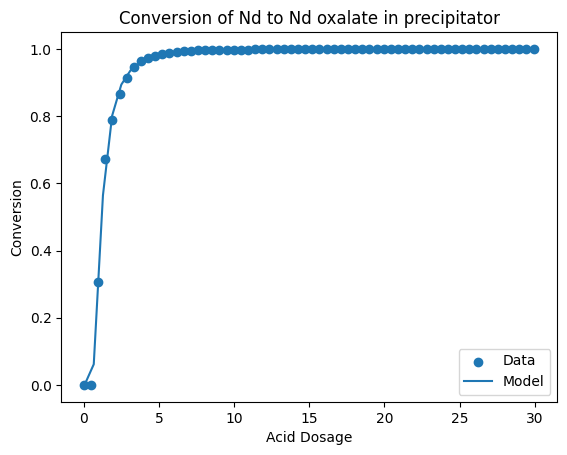

In [32]:
# Give calculated values to the variables
n_DA = {"Nd2(C2O4)3(s)": 2.419137}
eps = {"Nd2(C2O4)3(s)": 1.01030}

# Create an array for Oxalic acid dosage
oxalate = np.linspace(0.05, 30, 50)

# Create an empty list
Nd = []

# Calculate conversion for Nd oxalate
for i in range(len(oxalate)):
    Ndi = exp(-((eps["Nd2(C2O4)3(s)"] / (oxalate[i])) ** n_DA["Nd2(C2O4)3(s)"]))

    # Store results
    Nd.append(Ndi)

fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)

ax.scatter(data["Oxalate-2"], data["Nd2(C2O4)3(s)"], label="Data")
ax.plot(oxalate, Nd, label="Model")

plt.xlabel("Acid Dosage")
plt.ylabel("Conversion")
plt.title("Conversion of Nd to Nd oxalate in precipitator")

ax.legend()
plt.show

### Parity Plot

After the conversion under a function of acid dosage plot is generated, the parity plot is created to compare the actual values and prediction values.

The parity plot shows:

- Minteq conversion values on the horizontal axis
- Model predicted conversion values on the vertical axis

A diagonal line represents perfect agreement between 
 the Minteq data and model predictions.

Points close to the diagonal indicate accurate predictions, while
points far from the line indicate discrepancies.

Parity plots provide a compact and effective method for evaluating the
quality of parameter estimation results.

<function matplotlib.pyplot.show(close=None, block=None)>

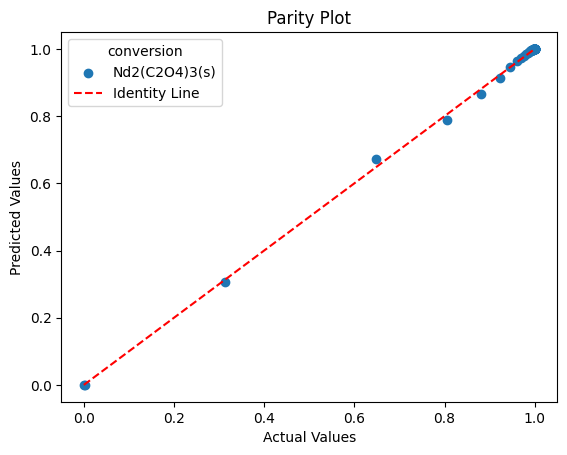

In [33]:
# Defining array with Minteq acid dosage
oxalic_acid_pp = data["Oxalate-2"].to_numpy()

# Creating empty list to store results
Nd_pp = []

# Re run equation to calculate conversion at experimental acid dosage
for i in range(len(oxalic_acid_pp)):
    Ndi_pp = exp(
        -((eps["Nd2(C2O4)3(s)"] / (oxalic_acid_pp[i])) ** n_DA["Nd2(C2O4)3(s)"])
    )

    # Store results
    Nd_pp.append(Ndi_pp)

fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)

ax.scatter(Nd_pp, data["Nd2(C2O4)3(s)"], label="Nd2(C2O4)3(s)")
plt.plot([0, 1], [0, 1], color="red", linestyle="--", label="Identity Line")

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Parity Plot")

ax.legend(title="conversion")
plt.show

## Step 4: Estimating Parameters for Multiple Species

This section extends the parameter estimation model from one species to multiple
species.

This allows:

- Consistent parameter estimation for each species
- Better representation of the real-world systems

The workflow follows steps similar to the single-species case but with
a larger model.

### 4.1 Create a New Model with Multiple Species 

We define a new Pyomo model that includes multiple species.

Each species has its own set of parameters:

- eps[i]
- n_DA[i]

The model calculates conversion for each species as a
function of oxalic acid dosage.

This formulation allows all species to be estimated simultaneously
within a single optimization model.

In [34]:
def isotherm_multiple():

    # Create a ConcreteModel object
    m = pyo.ConcreteModel()

    # Species names in the order they map to the integer index used below
    m.species_names = [
        "La2(C2O4)3(s)",
        "Nd2(C2O4)3(s)",
        "Gd2(C2O4)3(s)",
        "Ce2(C2O4)3(s)",
        "Y2(C2O4)3(s)",
        "Sm2(C2O4)3(s)",
        "Sc2(C2O4)3(s)",
        "Pr2(C2O4)3(s)",
        "Dy2(C2O4)3(s)",
    ]

    # parmest requires the first index of experiment_outputs to be an int/float
    # data point, so the species are indexed by integer position instead of name
    m.oxalates = list(range(len(m.species_names)))

    # Dictionaries with initial values to our parameters
    # parameter based on pH 1.5
    eps_init = {
        "Sc2(C2O4)3(s)": 6.4,
        "Y2(C2O4)3(s)": 4.5,
        "La2(C2O4)3(s)": 4.3,
        "Ce2(C2O4)3(s)": 1.1,
        "Pr2(C2O4)3(s)": 2.09,
        "Nd2(C2O4)3(s)": 1,
        "Sm2(C2O4)3(s)": 2.3,
        "Gd2(C2O4)3(s)": 3.1,
        "Dy2(C2O4)3(s)": 4.9,
    }

    # parameter based on pH 1.5
    N_D_init = {
        "Sc2(C2O4)3(s)": 6,
        "Y2(C2O4)3(s)": 4,
        "La2(C2O4)3(s)": 4,
        "Ce2(C2O4)3(s)": 2,
        "Pr2(C2O4)3(s)": 3,
        "Nd2(C2O4)3(s)": 2,
        "Sm2(C2O4)3(s)": 3,
        "Gd2(C2O4)3(s)": 4,
        "Dy2(C2O4)3(s)": 4,
    }

    # Create variables for parameters and variables, note they are indexed by integer position
    m.n_DA = pyo.Var(
        m.oxalates,
        initialize={i: N_D_init[name] for i, name in enumerate(m.species_names)},
        bounds=(1, 7),
    )
    m.eps = pyo.Var(
        m.oxalates,
        initialize={i: eps_init[name] for i, name in enumerate(m.species_names)},
        bounds=(1, 7),
    )
    m.conversion = pyo.Var(m.oxalates, initialize=0.1, bounds=(1e-8, 1))
    m.oxalic_dosage = pyo.Var(initialize=0.1, bounds=(1e-8, 30))

    # Create constraint now indexed by our list
    @m.Constraint(
        m.oxalates,
        doc="Conversion constraint",
    )
    def conversion_constraint(blk, t):
        return m.conversion[t] == exp(-((m.eps[t] / (m.oxalic_dosage)) ** m.n_DA[t]))

    # Fix variables to set up square problem
    fixed_n_DA = {
        "La2(C2O4)3(s)": 4.9,
        "Nd2(C2O4)3(s)": 2,
        "Gd2(C2O4)3(s)": 4.2,
        "Ce2(C2O4)3(s)": 2.7,
        "Y2(C2O4)3(s)": 4.7,
        "Sm2(C2O4)3(s)": 3.7,
        "Sc2(C2O4)3(s)": 2.3,
        "Pr2(C2O4)3(s)": 3.4,
        "Dy2(C2O4)3(s)": 4.7,
    }
    fixed_eps = {
        "La2(C2O4)3(s)": 4.3,
        "Nd2(C2O4)3(s)": 1,
        "Gd2(C2O4)3(s)": 3.1,
        "Ce2(C2O4)3(s)": 1.1,
        "Y2(C2O4)3(s)": 4.5,
        "Sm2(C2O4)3(s)": 2.3,
        "Sc2(C2O4)3(s)": 6.4,
        "Pr2(C2O4)3(s)": 2.1,
        "Dy2(C2O4)3(s)": 4.9,
    }
    for i, name in enumerate(m.species_names):
        m.eps[i].fix(fixed_eps[name])
        m.n_DA[i].fix(fixed_n_DA[name])

    m.oxalic_dosage.fix(1.425119)

    # Return initialized precipitation model
    return m

### 4.2 Define the Experiments with Multiple Species

We define a new Experiment class for the multi-species
model.

Each experiment now contains:

- An input condition (oxalic acid dosage amount)
- Multiple model outputs (species conversions)


In [35]:
class PrecipitationMultipleExperiment(Experiment):

    def __init__(self, data, experiment_number):
        self.data = data
        self.experiment_number = experiment_number
        self.data_i = data.iloc[experiment_number, :]
        self.model = None

    def create_model(self):
        self.model = m = isotherm_multiple()
        return m

    def finalize_model(self):
        m = self.model

        # Experiment inputs values
        m.oxalic_dosage = self.data_i["Oxalate-2"]

        # Experiment output values, mapped by integer index to species name
        for i, name in enumerate(m.species_names):
            m.conversion[i] = self.data_i[name]

        return m

    def label_model(self):
        m = self.model

        m.experiment_outputs = pyo.Suffix(direction=pyo.Suffix.LOCAL)
        m.experiment_outputs.update(
            [(m.conversion[i], self.data_i[name]) for i, name in enumerate(m.species_names)]
        )

        m.unknown_parameters = pyo.Suffix(direction=pyo.Suffix.LOCAL)
        m.unknown_parameters.update(
            (k, pyo.ComponentUID(k)) for i in m.oxalates for k in [m.n_DA[i], m.eps[i]]
        )

        return m

    def get_labeled_model(self):
        m = self.create_model()
        m = self.finalize_model()
        m = self.label_model()

        return m

### Sanity Check

Again, as a sanity check, we verify that the degrees of freedom are zero.

In [36]:
from idaes.core.util.model_statistics import degrees_of_freedom

# Testing the initialized model
test_data = {"oxalic_dosage": 1.425119}

m1 = isotherm_multiple()

m1.oxalic_dosage = test_data["oxalic_dosage"]

In [37]:
# Check that degrees of freedom is 0
print(degrees_of_freedom(m1))

0


Define a new array containing variables for each species.

In [38]:
variable_name = [
    "n_DA['La2(C2O4)3(s)']",
    "n_DA['Nd2(C2O4)3(s)']",
    "n_DA['Gd2(C2O4)3(s)']",
    "n_DA['Ce2(C2O4)3(s)']",
    "n_DA['Y2(C2O4)3(s)']",
    "n_DA['Sm2(C2O4)3(s)']",
    "n_DA['Sc2(C2O4)3(s)']",
    "n_DA['Pr2(C2O4)3(s)']",
    "n_DA['Dy2(C2O4)3(s)']",
    "eps['La2-(C2O4)3(s)']",
    "eps['Nd2-(C2O4)3(s)']",
    "eps['Gd2(C2O4)3(s)']",
    "eps['Ce2(C2O4)3(s)']",
    "eps['Y2(C2O4)3(s)']",
    "eps['Sm2(C2O4)3(s)']",
    "eps['Sc2(C2O4)3(s)']",
    "eps['Pr2(C2O4)3(s)']",
    "eps['Dy2(C2O4)3(s)']",
]

### 4.3 Solve the Parameter Estimation Model

We solve the multi-species parameter estimation problem.

The procedure is similar to the single-species case.

The solver will determine parameter values that best match the experimental
conversion data for all species simultaneously.

In [39]:
# Initialize a parameter estimation object
exp_list1 = []
for i in range(data.shape[0]):
    exp_list1.append(PrecipitationMultipleExperiment(data, i))

solver_options = {"tol": 1e-8}

# Create an estimator object
pest = parmest.Estimator(
    exp_list1, obj_function=SSE, solver_options=solver_options, tee=True
)

# Run parameter estimation using all data
obj_value, parameters = pest.theta_est()

Ipopt 3.13.2: tol=1e-08


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit http://projects.coin-or.org/Ipopt

This version of Ipopt was compiled from source code available at
    https://github.com/IDAES/Ipopt as part of the Institute for the Design of
    Advanced Energy Systems Process Systems Engineering Framework (IDAES PSE
    Framework) Copyright (c) 2018-2019. See https://github.com/IDAES/idaes-pse.

This version of Ipopt was compiled using HSL, a collection of Fortran codes
    for large-scale scientific computation.  All technical papers, sales and
    publicity material resulting from use of the HSL codes within IPOPT must
    contain the following acknowledgement:
        HSL, a collection of Fortran codes for large-scale scientific
        computation. S

### Display Results

The optimized parameters for all the species are displayed.

In [40]:
print()
print("The values for the parameters are as follows:")
species_names = exp_list1[0].model.species_names
for k, v in parameters.items():
    label = str(k)
    for i, name in enumerate(species_names):
        label = label.replace(f"[{i}]", f"[{name}]")
    print(f"{label} = {v:.4f}")


The values for the parameters are as follows:
n_DA[La2(C2O4)3(s)] = 4.6340
eps[La2(C2O4)3(s)] = 4.3717
n_DA[Nd2(C2O4)3(s)] = 2.4191
eps[Nd2(C2O4)3(s)] = 1.0103
n_DA[Gd2(C2O4)3(s)] = 4.1995
eps[Gd2(C2O4)3(s)] = 3.0728
n_DA[Ce2(C2O4)3(s)] = 2.7372
eps[Ce2(C2O4)3(s)] = 1.1885
n_DA[Y2(C2O4)3(s)] = 4.6740
eps[Y2(C2O4)3(s)] = 4.5518
n_DA[Sm2(C2O4)3(s)] = 3.7202
eps[Sm2(C2O4)3(s)] = 2.2962
n_DA[Sc2(C2O4)3(s)] = 2.3606
eps[Sc2(C2O4)3(s)] = 6.4203
n_DA[Pr2(C2O4)3(s)] = 3.4436
eps[Pr2(C2O4)3(s)] = 2.0960
n_DA[Dy2(C2O4)3(s)] = 4.7311
eps[Dy2(C2O4)3(s)] = 4.8608


### 4.4 Calculate Precipitation Isotherm with Optimized Parameters

After solving the parameter estimate model, the precipitation isotherm is developed over a
range of oxalic acid dosage values.

The calculated results show how conversion varies
with acid dosage for each species.

In [41]:
oxalate = np.linspace(0.05, 30, 50)

La = []
Nd = []
Gd = []
Ce = []
Y = []
Sm = []
Sc = []
Pr = []
Dy = []


n_DA = {
    "La2(C2O4)3(s)": 4.6340,
    "Nd2(C2O4)3(s)": 2.4191,
    "Gd2(C2O4)3(s)": 4.1995,
    "Ce2(C2O4)3(s)": 2.737238,
    "Y2(C2O4)3(s)": 4.67403,
    "Sm2(C2O4)3(s)": 3.7201,
    "Sc2(C2O4)3(s)": 2.3606,
    "Pr2(C2O4)3(s)": 3.44364,
    "Dy2(C2O4)3(s)": 4.73106,
}

eps = {
    "La2(C2O4)3(s)": 4.3717,
    "Nd2(C2O4)3(s)": 1.01030,
    "Gd2(C2O4)3(s)": 3.07276,
    "Ce2(C2O4)3(s)": 1.18848,
    "Y2(C2O4)3(s)": 4.6740,
    "Sm2(C2O4)3(s)": 2.296176,
    "Sc2(C2O4)3(s)": 6.42030,
    "Pr2(C2O4)3(s)": 2.09604,
    "Dy2(C2O4)3(s)": 4.8608,
}


for i in range(len(oxalate)):
    Lai = exp(-((eps["La2(C2O4)3(s)"] / (oxalate[i])) ** n_DA["La2(C2O4)3(s)"]))
    Ndi = exp(-((eps["Nd2(C2O4)3(s)"] / (oxalate[i])) ** n_DA["Nd2(C2O4)3(s)"]))
    Gdi = exp(-((eps["Gd2(C2O4)3(s)"] / (oxalate[i])) ** n_DA["Gd2(C2O4)3(s)"]))
    Cei = exp(-((eps["Ce2(C2O4)3(s)"] / (oxalate[i])) ** n_DA["Ce2(C2O4)3(s)"]))
    Yi = exp(-((eps["Y2(C2O4)3(s)"] / (oxalate[i])) ** n_DA["Y2(C2O4)3(s)"]))
    Smi = exp(-((eps["Sm2(C2O4)3(s)"] / (oxalate[i])) ** n_DA["Sm2(C2O4)3(s)"]))
    Sci = exp(-((eps["Sc2(C2O4)3(s)"] / (oxalate[i])) ** n_DA["Sc2(C2O4)3(s)"]))
    Pri = exp(-((eps["Pr2(C2O4)3(s)"] / (oxalate[i])) ** n_DA["Pr2(C2O4)3(s)"]))
    Dyi = exp(-((eps["Dy2(C2O4)3(s)"] / (oxalate[i])) ** n_DA["Dy2(C2O4)3(s)"]))

    La.append(Lai)
    Nd.append(Ndi)
    Gd.append(Gdi)
    Ce.append(Cei)
    Y.append(Yi)
    Sm.append(Smi)
    Sc.append(Sci)
    Pr.append(Pri)
    Dy.append(Dyi)

### 4.5 Make a New Plot with the Model Values

In this section, model predictions are plotted together with
experimental data.

The good fit shown in the plots indicates that, using the estimated parameters, the model
 simulates the precipitation behavior reasonably well.

<function matplotlib.pyplot.show(close=None, block=None)>

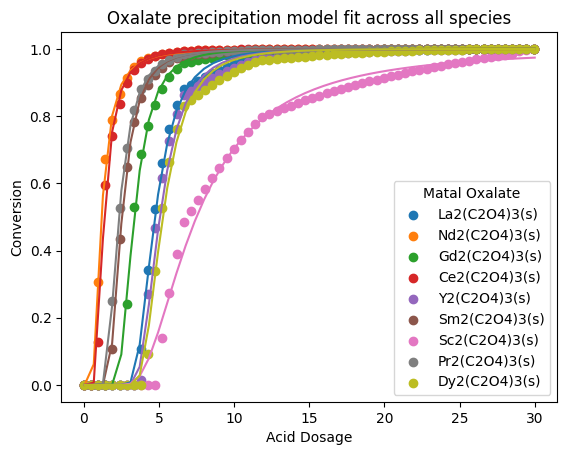

In [42]:
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)
ax.scatter(data["Oxalate-2"], data["La2(C2O4)3(s)"], label="La2(C2O4)3(s)")
ax.scatter(data["Oxalate-2"], data["Nd2(C2O4)3(s)"], label="Nd2(C2O4)3(s)")
ax.scatter(data["Oxalate-2"], data["Gd2(C2O4)3(s)"], label="Gd2(C2O4)3(s)")
ax.scatter(data["Oxalate-2"], data["Ce2(C2O4)3(s)"], label="Ce2(C2O4)3(s)")
ax.scatter(data["Oxalate-2"], data["Y2(C2O4)3(s)"], label="Y2(C2O4)3(s)")
ax.scatter(data["Oxalate-2"], data["Sm2(C2O4)3(s)"], label="Sm2(C2O4)3(s)")
ax.scatter(data["Oxalate-2"], data["Sc2(C2O4)3(s)"], label="Sc2(C2O4)3(s)")
ax.scatter(data["Oxalate-2"], data["Pr2(C2O4)3(s)"], label="Pr2(C2O4)3(s)")
ax.scatter(data["Oxalate-2"], data["Dy2(C2O4)3(s)"], label="Dy2(C2O4)3(s)")
ax.plot(oxalate, La)
ax.plot(oxalate, Nd)
ax.plot(oxalate, Gd)
ax.plot(oxalate, Ce)
ax.plot(oxalate, Y)
ax.plot(oxalate, Sm)
ax.plot(oxalate, Sc)
ax.plot(oxalate, Pr)
ax.plot(oxalate, Dy)

plt.xlabel("Acid Dosage")
plt.ylabel("Conversion")
plt.title("Oxalate precipitation model fit across all species")

ax.legend(title="Matal Oxalate")
plt.show

### 4.6 Compare Model Predictions with Experimental Data 

The model predictions are compared with
experimental data reported in the report from University of Kentucky:

Steven Keim, "Production of salable rare earths products from coal and coal byproducts in the U.S.
using advanced separation processes", 2019




In [43]:
oxalate1 = 6.4

La1 = []
Nd1 = []
Gd1 = []
Ce1 = []
Y1 = []
Sm1 = []
Sc1 = []
Pr1 = []
Dy1 = []

La1 = exp(-((eps["La2(C2O4)3(s)"] / (oxalate1)) ** n_DA["La2(C2O4)3(s)"]))
Nd1 = exp(-((eps["Nd2(C2O4)3(s)"] / (oxalate1)) ** n_DA["Nd2(C2O4)3(s)"]))
Gd1 = exp(-((eps["Gd2(C2O4)3(s)"] / (oxalate1)) ** n_DA["Gd2(C2O4)3(s)"]))
Ce1 = exp(-((eps["Ce2(C2O4)3(s)"] / (oxalate1)) ** n_DA["Ce2(C2O4)3(s)"]))
Y1 = exp(-((eps["Y2(C2O4)3(s)"] / (oxalate1)) ** n_DA["Y2(C2O4)3(s)"]))
Sm1 = exp(-((eps["Sm2(C2O4)3(s)"] / (oxalate1)) ** n_DA["Sm2(C2O4)3(s)"]))
Sc1 = exp(-((eps["Sc2(C2O4)3(s)"] / (oxalate1)) ** n_DA["Sc2(C2O4)3(s)"]))
Pr1 = exp(-((eps["Pr2(C2O4)3(s)"] / (oxalate1)) ** n_DA["Pr2(C2O4)3(s)"]))
Dy1 = exp(-((eps["Dy2(C2O4)3(s)"] / (oxalate1)) ** n_DA["Dy2(C2O4)3(s)"]))

bsarcm = np.array([La1, Nd1, Gd1, Ce1, Y1, Sm1, Sc1, Pr1, Dy1])

### 4.7 Make the Plot to Compare Model Predictions and Experimental Results

In this section, a plot is made to compare the model predictions using these
optimized parameters with experimental results from the UKy report.

The plot summarizes the performance of the multi-species parameter
estimation model and provides a validation for the model.

The plot demonstrates the performance of the model in predicting 
experimental results.

<function matplotlib.pyplot.show(close=None, block=None)>

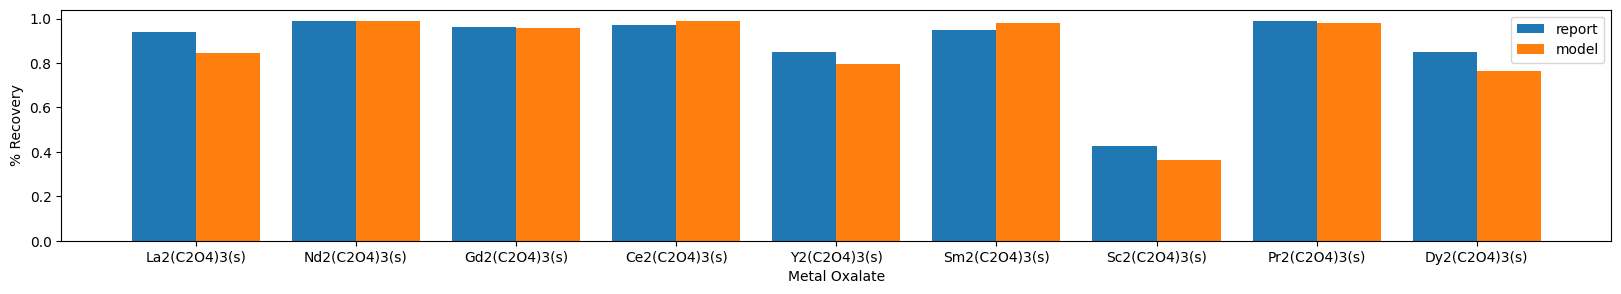

In [44]:
critical_minerals = [
    "La2(C2O4)3(s)",
    "Nd2(C2O4)3(s)",
    "Gd2(C2O4)3(s)",
    "Ce2(C2O4)3(s)",
    "Y2(C2O4)3(s)",
    "Sm2(C2O4)3(s)",
    "Sc2(C2O4)3(s)",
    "Pr2(C2O4)3(s)",
    "Dy2(C2O4)3(s)",
]

# Including arrays with data from report
datacm = [0.94, 0.99, 0.96, 0.97, 0.85, 0.95, 0.4281, 0.99, 0.85]
datax = [6.4, 6.4, 6.4, 6.4, 6.4, 6.4, 6.4, 6.4, 6.4]

X_axis = np.arange(len(critical_minerals))

fig = plt.figure(figsize=[20, 3])
ax = fig.add_subplot(1, 1, 1)

ax.bar(X_axis - 0.2, datacm, 0.4, label="report")
ax.bar(X_axis + 0.2, bsarcm, 0.4, label="model")

plt.xticks(X_axis, critical_minerals)
plt.xlabel("Metal Oxalate")
plt.ylabel("% Recovery")
plt.legend()
plt.show